Training shape: (60000, 171)
Test shape: (16000, 171)
Training missing values: 850015
Test missing values: 228680
br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
ab_000    46329
cr_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034
dtype: int64
Training missing values: 0
Test missing values: 0
aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64
Number of features: 170


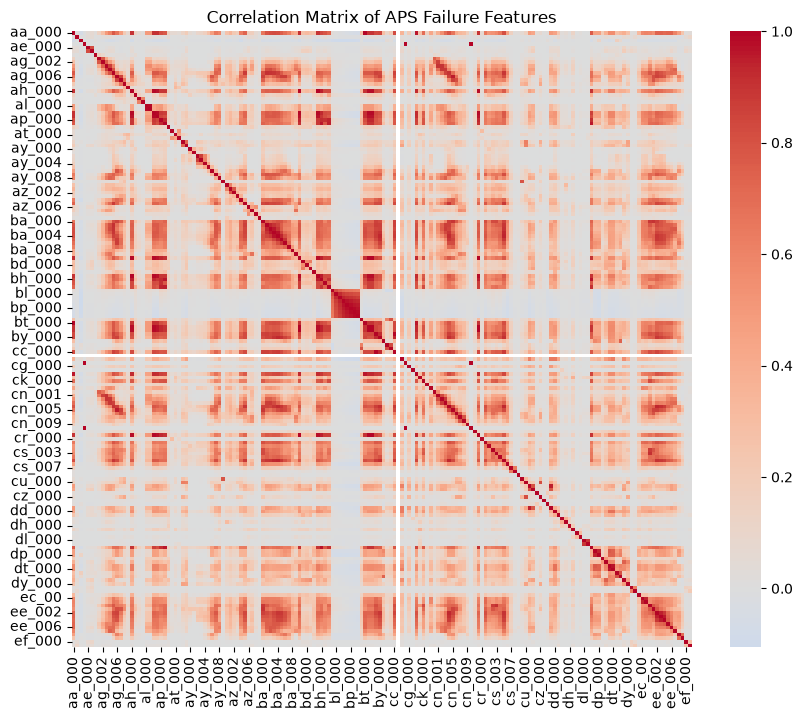

In [3]:
# 1a set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# loading the training and test datasets
train_df = pd.read_csv("aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("aps_failure_test_set.csv", skiprows=20, na_values="na")

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()


#1b missing value 
# 1bi types of techniques --> after researching, I decided to go ahead with median imputation.
print("Training missing values:", train_df.isna().sum().sum())
print("Test missing values:", test_df.isna().sum().sum())

# sorting missing values by feature
missing_values = train_df.isna().sum()
print(missing_values.sort_values(ascending=False).head(10))

from sklearn.impute import SimpleImputer

X_train = train_df.drop(columns=["class"]) # training
y_train = train_df["class"]
X_test = test_df.drop(columns=["class"]) # testing
y_test = test_df["class"]

imputer = SimpleImputer(strategy="median")

#fitting imputer
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

# checking missing values
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())


#1bii
# coeff variation for 170 features
cv = X_train.std() / X_train.mean()

print(cv)
print("Number of features:", len(cv))


#1biii CM
corr_matrix = X_train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)

plt.title("Correlation Matrix of APS Failure Features")
plt.show()



#1bi 
Common methods for handling missing values included mean, mode, median, KNN, and iterative imputations. I went ahead with median imputation as the dataset has numiercal features that might have skewed distributions and extreme outlier points. The median would be less sensitive to outliers. The SimpleImputer with strategy="median" would replace missing values and the imputer was fit on the training dataset then applied to both training and testing. 

#1bii The CV measures variability relative to the mean. In knowing this, the features with the highest CV resulted being cf_00 with 244.89, co_000 with 244.51, and ad_000 at 244.32. 

#1b iii
For the 170 features, a Pearson correlation was completed then visualized with a heatmap. THe matrix shows several clusters of positive correlations, indicating some features have overlapping information. The diagonal represents perfect self-correlation while the lighter areas illustrate weaker relationships between features. 

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64


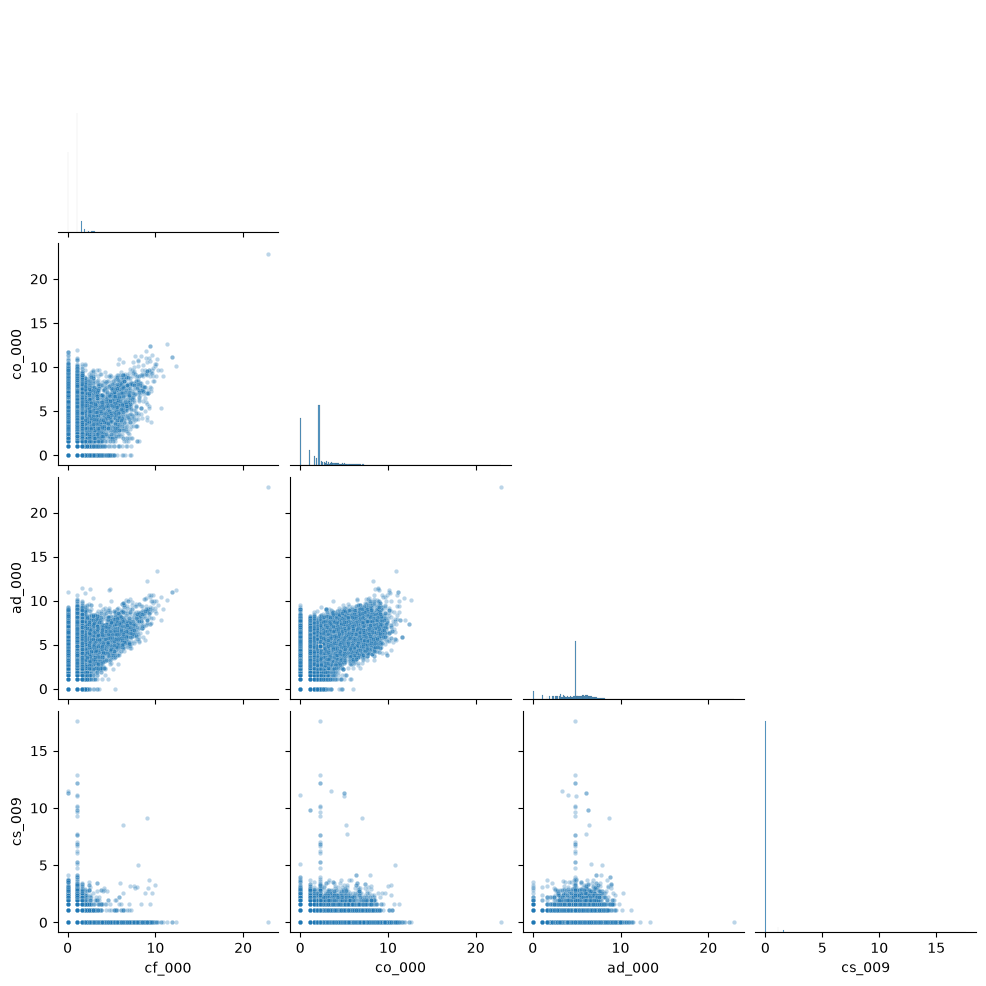

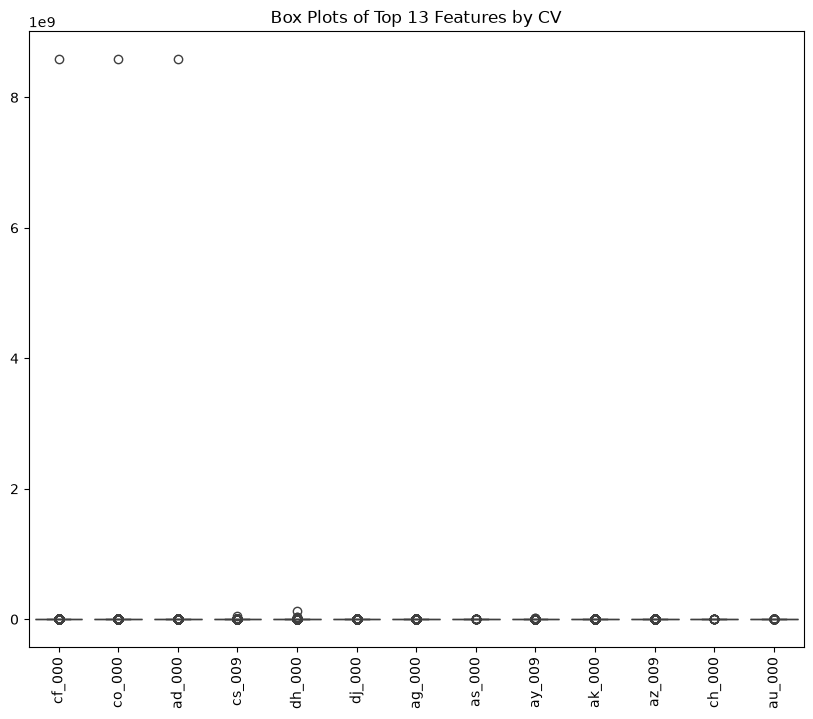

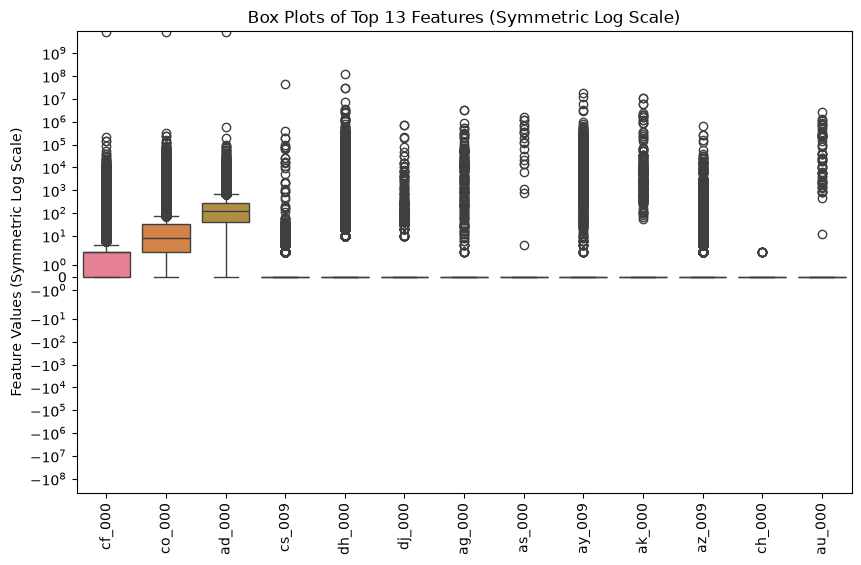

In [10]:
#1b iv 
# highest CV features 
top_features = cv.replace([np.inf, -np.inf], np.nan).dropna().nlargest(13)
print(top_features)

#naming top features 
top_13 = top_features.index.tolist()

#for i in range(0, len(top_13), 4):
    # selected = top_13[i:i+4]

    # sns.pairplot(
    #     X_train[selected],
    #     corner=True,
    #     plot_kws={"alpha": 0.3, "s": 10}
    # )
   # plt.show()


# Log-transform version for better visualization
X_log = np.log1p(X_train[top_13].clip(lower=0))

# Plot the first four features
sns.pairplot(
    X_log[top_13[:4]],
    corner=True,
    plot_kws={"alpha": 0.3, "s": 10}
)
plt.show()



# Box plots of the 13 selected features
plt.figure(figsize=(10, 8))
sns.boxplot(data=X_train[top_13])
plt.xticks(rotation=90)
plt.title("Box Plots of Top 13 Features by CV")
plt.show()



plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[top_13])
plt.yscale("symlog")
plt.xticks(rotation=90)
plt.title("Box Plots of Top 13 Features (Symmetric Log Scale)")
plt.ylabel("Feature Values (Symmetric Log Scale)")
plt.show()


#1b iv scatter and box plots
I took the top 13 features with the highest coefficients of variation, based on the square root of the total number of features. The scatter plots show that majority of the observations are near zero, with few extreme values. The outliers make it hard to visualized properly hence the utilization of log. There is little that can be concluded of statistical significance at this stage, though the high CV indicates substantial relative variability, it is not enough to identify being useful for predicting APS failures. 

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    98.333333
pos     1.666667
Name: proportion, dtype: float64


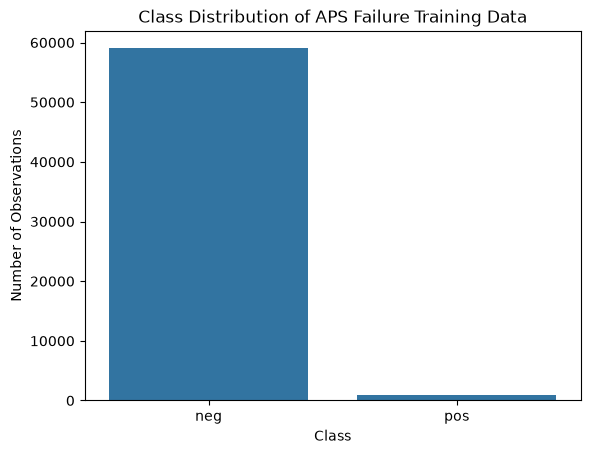

In [11]:
#class imbalance

class_counts = y_train.value_counts()
print(class_counts)
class_percentages = y_train.value_counts(normalize=True) * 100
print(class_percentages)


sns.countplot(x=y_train)
plt.title("Class Distribution of APS Failure Training Data")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.show()


#1b v 
The training data comes out to having 59000 negative observations and only 1000 positive observations. There is a significant class imbalance, which could lead to classification models to be bias toward the negative class, ultimately reducing the correct ability to identify APS failures. 

Random Forest training complete
Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Misclassification Rate: 1.666666666666483e-05

Test Confusion Matrix:
[[15610    15]
 [  106   269]]
Test Misclassification Rate: 0.0075625000000000275


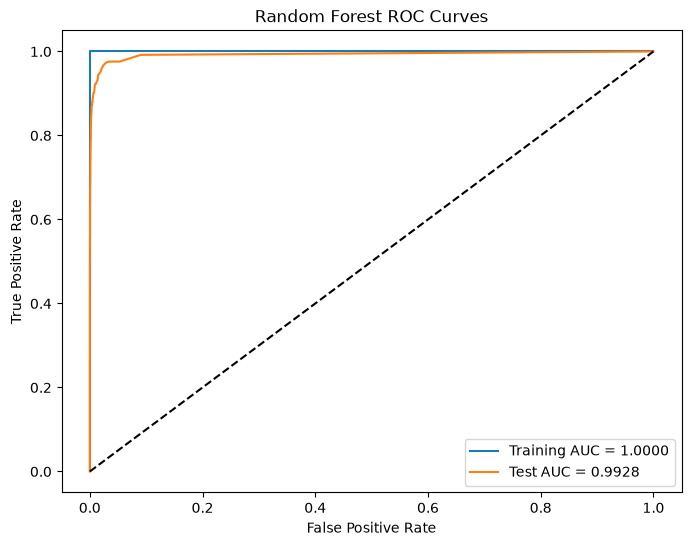

Training AUC: 1.0
Test AUC: 0.992754432
OOB Error: 0.006116666666666659
Test Error: 0.0075625000000000275
Difference: 0.0014458333333333684


In [12]:
#1c Random forest classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score


rf = RandomForestClassifier( #removing class imbalance 
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
print("Random Forest training complete")


y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# predicting probs for positive class
pos_index = list(rf.classes_).index("pos")
y_train_prob = rf.predict_proba(X_train)[:, pos_index]
y_test_prob = rf.predict_proba(X_test)[:, pos_index]

# CMs 
train_cm = confusion_matrix(
    y_train, y_train_pred, labels=["neg", "pos"]
)
test_cm = confusion_matrix(
    y_test, y_test_pred, labels=["neg", "pos"]
)

# misclassification rates
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print("Training Confusion Matrix:")
print(train_cm)
print("Training Misclassification Rate:", train_error)

print("\nTest Confusion Matrix:")
print(test_cm)
print("Test Misclassification Rate:", test_error)



# actual classes to binary
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

# ROC curves
fpr_train, tpr_train, _ = roc_curve(
    y_train_binary, y_train_prob
)
fpr_test, tpr_test, _ = roc_curve(
    y_test_binary, y_test_prob
)

# AUC
train_auc = roc_auc_score(y_train_binary, y_train_prob)
test_auc = roc_auc_score(y_test_binary, y_test_prob)

# ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train, label=f"Training AUC = {train_auc:.4f}")
plt.plot(fpr_test, tpr_test, label=f"Test AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)


# OOB error
oob_error = 1 - rf.oob_score_

print("OOB Error:", oob_error)
print("Test Error:", test_error)
print("Difference:", abs(oob_error - test_error))



#1c random forest
I trained random forest classifier with 100 trees without compensating for class imbalance. The model acheived a training AUC of 1.0 and a test AUC of 0.9928, this proved a strong overall classification conclusion. 

The misclassification rate for the training set was 0.0017% while the test misclassification rate was 0.7563%. The test confusion matrix showed 106 false negatives and 15 false positives. Althoguh the model achieved high overall accuracy, it correctly identified 269 of the 375 positive cases. From prior remarks, this seems to suggest that the class imbalance does impact the model's ability to identify APS failures, regardles of its strong performance. 

In [ ]:
#1d compensate and repeat
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)
print("Balanced Random Forest training complete")


# predicting
y_train_pred_bal = rf_balanced.predict(X_train)
y_test_pred_bal = rf_balanced.predict(X_test)

# CMs calculation
train_cm_bal = confusion_matrix(
    y_train, y_train_pred_bal, labels=["neg", "pos"]
)
test_cm_bal = confusion_matrix(
    y_test, y_test_pred_bal, labels=["neg", "pos"]
)

# misclassification rates
train_error_bal = 1 - accuracy_score(y_train, y_train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, y_test_pred_bal)

print("Balanced Training Confusion Matrix:")
print(train_cm_bal)
print("Training Misclassification Rate:", train_error_bal)
print("\nBalanced Test Confusion Matrix:")
print(test_cm_bal)
print("Test Misclassification Rate:", test_error_bal)



# predicting probs for positive class
pos_index_bal = list(rf_balanced.classes_).index("pos")

y_train_prob_bal = rf_balanced.predict_proba(X_train)[:, pos_index_bal]
y_test_prob_bal = rf_balanced.predict_proba(X_test)[:, pos_index_bal]

# ROC curves
fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train_binary, y_train_prob_bal
)
fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test_binary, y_test_prob_bal
)

# AUC
train_auc_bal = roc_auc_score(y_train_binary, y_train_prob_bal)
test_auc_bal = roc_auc_score(y_test_binary, y_test_prob_bal)

# ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_train_bal, tpr_train_bal,
         label=f"Training AUC = {train_auc_bal:.4f}")

plt.plot(fpr_test_bal, tpr_test_bal,
         label=f"Test AUC = {test_auc_bal:.4f}")

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()
print("Training AUC:", train_auc_bal)
print("Test AUC:", test_auc_bal)


# calculating balanced Random Forest OOB error
oob_error_bal = 1 - rf_balanced.oob_score_
print("Balanced OOB Error:", oob_error_bal)
print("Balanced Test Error:", test_error_bal)
print("Difference:", abs(oob_error_bal - test_error_bal))



comparison = pd.DataFrame({
    "Metric": ["Test Error", "Test AUC", "OOB Error",
               "False Negatives", "False Positives"],
    "Unbalanced RF": [
        test_error,
        test_auc,
        oob_error,
        test_cm[1, 0],
        test_cm[0, 1]
    ],
    "Balanced RF": [
        test_error_bal,
        test_auc_bal,
        oob_error_bal,
        test_cm_bal[1, 0],
        test_cm_bal[0, 1]
    ]
})

print(comparison)